In [1]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
%matplotlib inline
import pickle
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd
from openTSNE import TSNE

env: CUDA_VISIBLE_DEVICES=1


In [6]:
dataset = "yao_10x"
res_path = os.path.join("/home/sdamrich/CIN/submissions/ne_aligned/data_sharing/yao_10x_ent_l2l3")

In [7]:
x_ent = np.load(os.path.join(res_path, "ent_l2l3_pca50.npy"))

meta_ent = pd.read_csv(os.path.join(res_path, "ent_l2l3_meta.csv"))

In [8]:
x_ent.shape

(26588, 50)

In [12]:
b1_ent = x_ent[meta_ent["donor_sex_label"] == "M"]
b2_ent = x_ent[meta_ent["donor_sex_label"] == "F"]


In [13]:
b1_ent.shape

(11352, 50)

In [28]:
cluster_idx = meta_ent["cluster_order"] - meta_ent["cluster_order"].min()

cluster_idx_b1 = cluster_idx[meta_ent["donor_sex_label"] == "M"]
cluster_idx_b2 = cluster_idx[meta_ent["donor_sex_label"] == "F"]

In [43]:
cluster_batch_vectors = []

for cluster_id in range(cluster_idx.max()+1):
    if (cluster_idx_b1 == cluster_id).sum() == 0 or  (cluster_idx_b2 == cluster_id).sum() == 0:
        continue
    cluster_mean_b1 = b1_ent[cluster_idx_b1 == cluster_id].mean(0)
    cluster_mean_b2 = b2_ent[cluster_idx_b2 == cluster_id].mean(0)
    cluster_batch_vectors.append(cluster_mean_b2-cluster_mean_b1)
    if np.any(np.isnan(cluster_batch_vectors[-1])):
        print(cluster_id)
        print()
cluster_batch_vectors = np.array(cluster_batch_vectors)

In [44]:
cluster_batch_vectors.shape

(21, 50)

In [49]:
norms = np.linalg.norm(cluster_batch_vectors, 2, axis=1)
norms

array([10.76358161, 11.32854066, 11.17987489,  9.6475759 , 10.13116906,
        8.51880445,  9.68008125,  9.678789  ,  8.71953202,  8.80292981,
       11.39953976,  9.31325707,  9.79931646, 10.00853281, 11.26157888,
        8.99459096, 12.11611997,  9.41077076, 14.37533031,  9.1470243 ,
        9.59971521])

In [60]:
cos = ((cluster_batch_vectors / norms[:, None])[None, : ] *  (cluster_batch_vectors / norms[:, None])[:, None]).sum(-1)
ind = np.triu_indices(len(cos), k=1)
cos_flat = cos[ind]

(array([ 2.,  1.,  8.,  8.,  2.,  8., 11., 15., 79., 76.]),
 array([0.3092283 , 0.37706917, 0.44491004, 0.51275091, 0.58059178,
        0.64843265, 0.71627352, 0.78411439, 0.85195526, 0.91979613,
        0.987637  ]),
 <BarContainer object of 10 artists>)

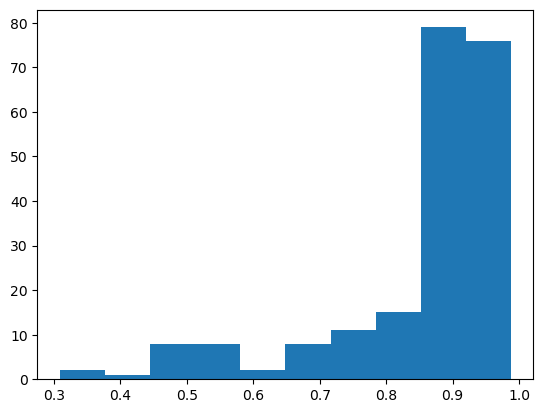

In [61]:
plt.hist(cos_flat)
# --> most vectors are parallel

(array([1., 0., 0., 0., 1., 0., 1., 3., 6., 9.]),
 array([0.57056083, 0.61350475, 0.65644867, 0.69939258, 0.7423365 ,
        0.78528042, 0.82822433, 0.87116825, 0.91411217, 0.95705608,
        1.        ]),
 <BarContainer object of 10 artists>)

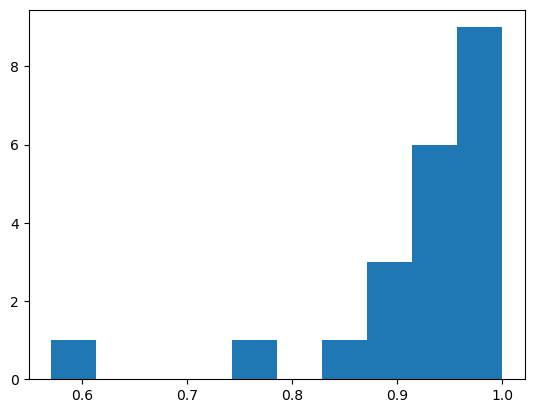

In [62]:
plt.hist(cos[:, 0])

In [63]:
mean_batch_vector = np.mean(cluster_batch_vectors, axis=0)

In [64]:
batch_vector = b2_ent.mean(0)-b1_ent.mean(0)

In [65]:
mean_batch_vector - batch_vector

array([-0.08494309,  0.10859494,  0.11676293, -0.02693302,  0.22805219,
       -0.21485843, -0.16738507, -0.20778136, -0.17215442, -0.13190806,
        0.11845252,  0.07615914,  0.15052654,  0.05914959,  0.07299029,
       -0.12719952, -0.06321284,  0.23166251,  0.04444224, -0.27483888,
       -0.11422534, -0.30722737, -0.21362045, -0.38552167, -0.122676  ,
        0.15053149, -0.13730093, -0.25195533, -0.20689013,  0.11945591,
        0.34107107,  0.31437605, -0.19381956, -0.15384756, -0.41270493,
       -0.07394549,  0.12522659,  0.20617925, -0.04060292,  0.10891456,
       -0.15168322, -0.01381078,  0.22781139, -0.13651156, -0.01409864,
       -0.53731465,  0.19933558, -0.21678308, -0.22820572,  0.02230255])

In [66]:
mean_batch_vector

array([-2.50505700e+00, -1.98019006e+00, -1.62501757e+00, -1.95336885e+00,
       -1.08136269e+00, -5.70895329e-01,  1.13563206e+00,  2.92399135e-01,
       -4.35651347e-01,  1.10376874e+00,  5.23438323e-01, -6.62487376e-01,
        1.97261017e+00, -1.31226527e+00, -4.89555116e-01, -1.09013450e+00,
       -3.75728169e-01, -3.35310511e+00,  1.90292131e+00, -4.33666486e-02,
       -4.29951659e+00,  3.04096866e+00,  5.99438589e-01,  1.06890463e+00,
        2.29424570e+00,  7.55856909e-01,  1.23603403e+00,  7.45706001e-01,
       -1.24641183e+00,  7.88447694e-02, -7.78614803e-01,  1.74590551e+00,
        6.09881524e-01, -2.82375637e-01, -2.56277754e-02, -1.77039065e-01,
        6.03552994e-01, -4.11048925e-01,  4.87547438e-01, -2.51883671e-01,
       -2.12613293e-03,  5.52664934e-01, -1.01380857e-01,  4.56432270e-02,
       -1.80580802e-01, -1.94482219e-01,  2.39172889e-01,  1.85248387e-01,
        5.54452465e-02,  6.79988672e-02])

In [67]:
from sklearn.decomposition import PCA

In [137]:
pca1  = PCA(50)
pca1.fit(b1_ent)

pca2 = PCA(50)
pca2.fit(b2_ent)


,n_components,50
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [138]:
pca1.components_[:5].shape

(5, 50)

In [139]:
np.linalg.norm(pca1.components_[:5], 2, axis=1)

array([1., 1., 1., 1., 1.])

In [140]:
from scipy.linalg import subspace_angles

In [141]:
k=10
V0 = pca1.components_[:k].T   # (D, k), orthonormal columns
V1 = pca2.components_[:k].T
print("principal angles (deg):", np.round(np.degrees(subspace_angles(V0, V1)), 1))

principal angles (deg): [63.3 25.  12.4  8.9  7.3  6.7  5.2  4.1  3.3  2.6]


In [142]:
V0.shape

(50, 10)

In [143]:
a = pca1.components_ @ batch_vector    
print(a.shape)                          # coords of b in the within-batch basis
frac_cum = np.cumsum(a**2) / (a**2).sum()
print(frac_cum)

(50,)
[0.03079277 0.13251711 0.17377361 0.18493038 0.30021472 0.31310566
 0.32727305 0.32939832 0.3326341  0.33695457 0.33709408 0.3380977
 0.34107073 0.34715958 0.35388356 0.35454246 0.35474187 0.35484736
 0.35489877 0.35500896 0.35585068 0.35593898 0.35594493 0.35627652
 0.35647393 0.35757064 0.35809153 0.35875549 0.35973928 0.3604202
 0.36118625 0.36119359 0.36143405 0.36146906 0.36151804 0.36154757
 0.36155321 0.36569622 0.36582371 0.36613369 0.36641225 0.36840776
 0.3685004  0.36866699 0.36935987 0.36992241 0.37096874 0.37109216
 0.37109756 1.        ]


In [89]:
np.cumsum(pca1.explained_variance_ratio_)

array([0.34393103, 0.456215  , 0.54057214, 0.60346512, 0.6385529 ,
       0.66709062, 0.69082946, 0.71175862, 0.72833105, 0.74186948,
       0.75437823, 0.76610744, 0.77650234, 0.78661917, 0.79610472,
       0.8052835 , 0.81409259, 0.82243745, 0.83066281, 0.83862485,
       0.8465073 , 0.85416451, 0.86148343, 0.86866254, 0.87556064,
       0.88229744, 0.88886667, 0.89520567, 0.90134927, 0.9073927 ,
       0.91337059, 0.91928961, 0.92500752, 0.93057324, 0.93594906,
       0.9411857 , 0.9463577 , 0.95143035, 0.95639136, 0.96125784,
       0.96593691, 0.97054651, 0.97507673, 0.97947923, 0.98367443])

In [123]:
a = pca1.components_[:45] @ batch_vector    
f = (a@a) / (batch_vector@batch_vector)
print(f"Squared norm fraction: {f}")
print(f"Angle: θ_k = {np.arccos(np.sqrt(f))} ")

Squared norm fraction: 0.3693598652258471
Angle: θ_k = 0.9175723174145942 


In [130]:
a = pca2.components_[:5] @ batch_vector    
f = (a@a) / (batch_vector@batch_vector)
print(f"Squared norm fraction: {f}")
print(f"Angle: θ_k  = {np.rad2deg(np.arccos(np.sqrt(f)))}   ")

Squared norm fraction: 0.28062433921608115
Angle: θ_k  = 58.012118826547855   


In [134]:
for i in range(10):
    r = np.random.randn(b1_ent.shape[1])
    r /= np.linalg.norm(r)
    a = pca1.components_[:10] @ r
    f = (a@a)
    print(f"Squared norm fraction: {f}")
    print(f"Angle: θ_k  = {np.rad2deg(np.arccos(np.sqrt(f)))}   ")
    print()

Squared norm fraction: 0.41157039449782773
Angle: θ_k  = 50.093435445378084   

Squared norm fraction: 0.36618402634341496
Angle: θ_k  = 52.761701191298016   

Squared norm fraction: 0.18938126740392283
Angle: θ_k  = 64.20327857791553   

Squared norm fraction: 0.1411224249694863
Angle: θ_k  = 67.9347255650406   

Squared norm fraction: 0.25218808594060915
Angle: θ_k  = 59.8554473422111   

Squared norm fraction: 0.23311645079081977
Angle: θ_k  = 61.13016882080805   

Squared norm fraction: 0.2142932283643788
Angle: θ_k  = 62.424427679394896   

Squared norm fraction: 0.198525109600043
Angle: θ_k  = 63.54072677038986   

Squared norm fraction: 0.09125448096999715
Angle: θ_k  = 72.41720999522998   

Squared norm fraction: 0.2097471688215659
Angle: θ_k  = 62.7430580491787   



In [112]:
D = x_ent.shape[1]
rand_null = np.arange(1, D + 1) / D
for kk in (1, 2, 3, 5, 10):
    print(f"top-{kk:>2}: f_k={frac_cum[kk-1]:.3f}  random={rand_null[kk-1]:.3f}  "
          f"angle={np.degrees(np.arccos(np.sqrt(frac_cum[kk-1]))):.1f}°")

top- 1: f_k=0.083  random=0.020  angle=73.2°
top- 2: f_k=0.359  random=0.040  angle=53.2°
top- 3: f_k=0.470  random=0.060  angle=46.7°
top- 5: f_k=0.813  random=0.100  angle=25.6°
top-10: f_k=0.912  random=0.200  angle=17.2°


In [135]:
D = x_ent.shape[1]
rand_null = np.arange(1, D + 1) / D
for kk in (1, 2, 3, 5, 10):
    print(f"top-{kk:>2}: f_k={frac_cum[kk-1]:.3f}  random={rand_null[kk-1]:.3f}  "
          f"angle={np.degrees(np.arccos(np.sqrt(frac_cum[kk-1]))):.1f}°")

top- 1: f_k=0.083  random=0.020  angle=73.2°
top- 2: f_k=0.359  random=0.040  angle=53.2°
top- 3: f_k=0.470  random=0.060  angle=46.7°
top- 5: f_k=0.813  random=0.100  angle=25.6°
top-10: f_k=0.912  random=0.200  angle=17.2°


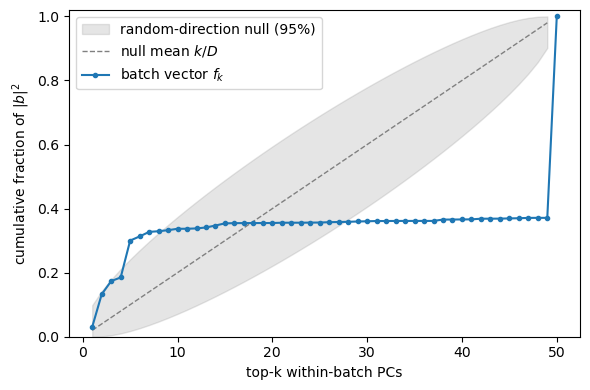

In [144]:
from scipy.stats import beta

D = x_ent.shape[1]
ks = np.arange(1, D)                       # 1..D-1; k=D is trivially 1 (Beta degenerate)
lo  = beta.ppf(0.025, ks/2, (D - ks)/2)
hi  = beta.ppf(0.975, ks/2, (D - ks)/2)

fig, ax = plt.subplots(figsize=(6, 4))
ax.fill_between(ks, lo, hi, color="gray", alpha=0.2,
                label="random-direction null (95%)")
ax.plot(ks, ks/D, color="gray", ls="--", lw=1, label=r"null mean $k/D$")
ax.plot(np.arange(1, D + 1), frac_cum, "-o", ms=3, color="C0",
        label=r"batch vector $f_k$")
ax.set(xlabel="top-k within-batch PCs",
       ylabel=r"cumulative fraction of $\|b\|^2$", ylim=(0, 1.02))
ax.legend()
plt.tight_layout()

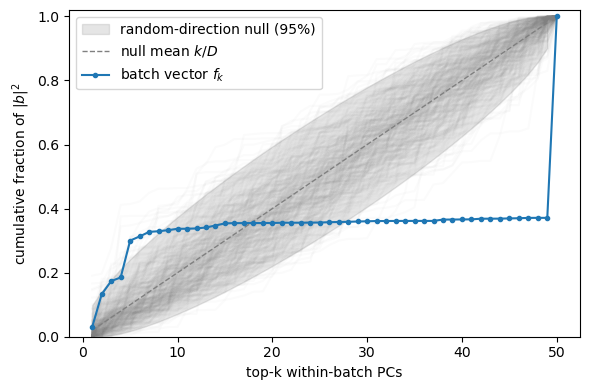

In [145]:
rng = np.random.default_rng(0)
kk = np.arange(1, D + 1)
for _ in range(300):
    a = rng.standard_normal(D)
    ax.plot(kk, np.cumsum(a**2) / np.sum(a**2), color="gray", alpha=0.03, zorder=0)
fig                                        # redisplay

In [150]:
Xw = np.vstack([b1_ent-b1_ent.mean(0), b2_ent-b2_ent.mean(0)])
pca_w= PCA()
Vw = pca_w.fit(Xw).components_          # (D, D), within-batch PC directions


In [151]:

print("mass of b in last within-batch PC:", float((Vw[-1] @ batch_vector)**2 / (batch_vector @ batch_vector)))
print("within-batch variance, last 5 PCs:", np.round(pca_w.explained_variance_[-5:], 6))

mass of b in last within-batch PC: 0.6241553027351957
within-batch variance, last 5 PCs: [2.979267 2.843841 2.719351 2.562437 0.908132]


In [154]:
# check if the 30% batch vector alignment confuses cell types
k = 5
Vk = Vw[:k]                          # top-k biological directions (rows)
b_bio = Vk @ batch_vector                       # batch shift, in biological-subspace coords
print("‖b_bio‖ (batch shift in bio subspace):", np.linalg.norm(b_bio))

# spacing of biology in the SAME subspace: distances between cell-type centroids within one batch
from scipy.spatial.distance import pdist
labels = meta_ent["cluster_label"].values      # or "cluster_label" for finer types
m0 = meta_ent["donor_sex_label"] == "M"
cents = np.array([Vk @ x_ent[m0 & (labels == c)].mean(0)
                  for c in np.unique(labels[m0])])
d_bio = np.median(pdist(cents))
print("median between-type distance in bio subspace:", d_bio)
print("ratio (batch shift / type spacing):", np.linalg.norm(b_bio) / d_bio)

‖b_bio‖ (batch shift in bio subspace): 5.523272200321826
median between-type distance in bio subspace: 23.487663671161457
ratio (batch shift / type spacing): 0.23515630492884618


In [155]:
dists = pdist(cents)
print("min / 10% / median between-type dist:",
      round(dists.min(), 1), round(np.quantile(dists, 0.1), 1), round(np.median(dists), 1))
print("ratio to nearest type pair:", round(np.linalg.norm(b_bio) / dists.min(), 2))

# within-type spread in the same subspace (types are clouds, not points)
import numpy as np
spreads = [np.sqrt(((Vk @ x_ent[m0 & (labels == c)].T).T
                    - (Vk @ x_ent[m0 & (labels == c)].mean(0))).var(0).sum())
           for c in np.unique(labels[m0])]
print("median within-type spread:", round(np.median(spreads), 1))

min / 10% / median between-type dist: 4.4 10.6 23.5
ratio to nearest type pair: 1.26
median within-type spread: 8.2


In [157]:
m0 = meta_ent["donor_sex_label"] == "M"
m1 = meta_ent["donor_sex_label"] == "M"

In [158]:
from sklearn.neighbors import NearestNeighbors

X0, X1 = x_ent[m0], x_ent[m1]
lab0, lab1 = labels[m0], labels[m1]
kmnn = 15
nn01 = NearestNeighbors(n_neighbors=kmnn).fit(X1).kneighbors(X0, return_distance=False)
nn10 = NearestNeighbors(n_neighbors=kmnn).fit(X0).kneighbors(X1, return_distance=False)

set10 = [set(r) for r in nn10]
mutual = np.array([(i, j) for i, row in enumerate(nn01) for j in row if i in set10[j]])
same = (lab0[mutual[:, 0]] == lab1[mutual[:, 1]]).mean()
print(f"{len(mutual)} MNN pairs, {same:.1%} link the same subclass")

68714 MNN pairs, 81.6% link the same subclass


In [173]:
import ot
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(0)

def subsample(mask, n=1000):
    idx = np.where(mask)[0]
    return idx if len(idx) <= n else rng.choice(idx, n, replace=False)

i0, i1 = subsample(m0), subsample(m1)
X0, X1 = x_ent[i0], x_ent[i1]
lab0, lab1 = labels[i0], labels[i1]
n0, n1 = len(X0), len(X1)
same = (lab0[:, None] == lab1[None, :])          # n0 x n1, same subclass
print("subsampled sizes:", n0, n1)

# ---- MNN ----
kmnn = 15
nn01 = NearestNeighbors(n_neighbors=kmnn).fit(X1).kneighbors(X0, return_distance=False)
nn10 = NearestNeighbors(n_neighbors=kmnn).fit(X0).kneighbors(X1, return_distance=False)
set10 = [set(r) for r in nn10]
mutual = np.array([(i, j) for i, row in enumerate(nn01) for j in row if i in set10[j]])
mnn_same = (lab0[mutual[:, 0]] == lab1[mutual[:, 1]]).mean()
print(f"MNN: {len(mutual)} pairs, {mnn_same:.1%} link same subclass")

# ---- OT ----
a = np.ones(n0) / n0
b_marg = np.ones(n1) / n1
M = ot.dist(X0, X1)
M /= np.median(M)
for reg in (0.05, 0.1, 1):
    P = ot.sinkhorn(a, b_marg, M, reg=reg, numItermax=3000)
    print(f"OT reg={reg:<5} mass-concordance={P[same].sum():.1%}  "
          f"argmax={ (lab0 == lab1[P.argmax(1)]).mean():.1%}")

subsampled sizes: 1000 1000
MNN: 6925 pairs, 72.3% link same subclass
OT reg=0.05  mass-concordance=62.9%  argmax=71.3%
OT reg=0.1   mass-concordance=52.5%  argmax=72.8%
OT reg=1     mass-concordance=18.1%  argmax=68.4%


In [174]:
cats = np.unique(np.concatenate([lab0, lab1]))
p0 = np.array([(lab0 == c).mean() for c in cats])
p1 = np.array([(lab1 == c).mean() for c in cats])
print("chance same-subclass:", f"{(p0 * p1).sum():.1%}")

chance same-subclass: 10.9%


In [175]:
P = ot.emd(a, b_marg, M)
print(f"exact OT (EMD): {P[same].sum():.1%} same subclass")

exact OT (EMD): 71.9% same subclass
